In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from msuthemes import theme_msu, colors
from scipy.signal import find_peaks
from moviepy.editor import VideoFileClip
import warnings
warnings.simplefilter("ignore")

In [2]:

# ==========================================
# 1. CONFIGURATION
# ==========================================
RESULTS_DIR = "../data/04_analysis/reversecorrelation_manipulated/"
MOVIE_PATH = '../data/00_raw_data/99_movie_stimulus/Partly_Cloudy_Modified.mov'   
OUTPUT_DIR = '../data/04_analysis/reversecorrelation_manipulated/'    
os.makedirs(OUTPUT_DIR, exist_ok=True)

FS            = 20                             # Sampling rate (Hz)
GSR_LAG       = 4.5                       # Seconds to rewind from peak (biological delay)
CLIP_DURATION = 3.0                 # Duration of the snippet (seconds)

# Peak Detection Settings (Tweak these based on your Z-score data!)
MIN_HEIGHT    = 1.    # Minimum amplitude (in Z-score units, usually >0.5 or >1.0)
MIN_DIST_SEC  = 5   # Minimum seconds between peaks (to avoid double-counting one event)
PROMINENCE    = 1.5    # How much the peak stands out from the surrounding baseline

# Create output folder
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==========================================
# 2. LOAD DATA 
# ==========================================
tc_df = pd.read_csv(os.path.join(RESULTS_DIR, f"GSR_split_timecourse.csv"))
tc_df['Average'] = (tc_df['Group_1'] + tc_df['Group_2']) / 2

# specific check to ensure your dataframe is ready
if 'Average' not in tc_df.columns or 'Time_Sec' not in tc_df.columns:
    raise ValueError("DataFrame must contain 'Average' and 'Time' columns")

# ==========================================
# 3. SIGNAL PROCESSING: FIND PEAKS
# ==========================================

# Optional: Smooth the signal slightly before peak detection 
# (GSR is slow; individual jitters at 20Hz might cause false peaks)
window_size = int(FS * 1.0) # 1 second smoothing
tc_df['Smooth_GSR'] = tc_df['Average'].rolling(window=window_size, center=True).mean().fillna(tc_df['Average'])

# Find Peaks
# distance is in samples, so we multiply seconds by sampling rate
peaks_indices, properties = find_peaks(
    tc_df['Smooth_GSR'], 
    height=MIN_HEIGHT, 
    distance=MIN_DIST_SEC * FS,
    prominence=PROMINENCE
)

print(f"Found {len(peaks_indices)} peaks in the group physiological signal.")


FileNotFoundError: [Errno 2] No such file or directory: '../data/04_analysis/reversecorrelation_manipulated/GSR_split_timecourse.csv'

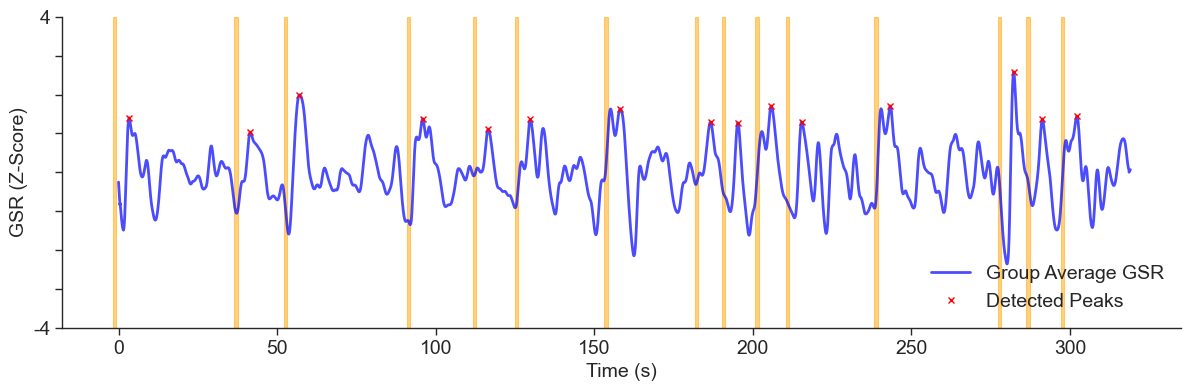


Done! Clips are in the folder: ../data/04_analysis/reversecorrelation_manipulated/


In [3]:
# ==========================================
# VISUALIZATION (Sanity Check)
# ==========================================
sns.set_theme(font='Arial')

sns.set(style="ticks", context="paper")

plt.figure(figsize=(12, 4))
plt.plot(tc_df['Time_Sec'], tc_df['Smooth_GSR'], label='Group Average GSR', color='blue', lw = 2, alpha=0.7)
plt.plot(tc_df.iloc[peaks_indices]['Time_Sec'], tc_df.iloc[peaks_indices]['Smooth_GSR'], "x", color='red', label='Detected Peaks')

# Visualize the lag
for idx in peaks_indices:
    peak_t = tc_df.iloc[idx]['Time_Sec']
    trigger_t = peak_t - GSR_LAG
    plt.axvspan(trigger_t - 0.5, trigger_t + 0.5, color='orange', alpha=0.5)

#plt.title(f"Reverse Correlation: Peaks (Red X) and Estimated Narrative Triggers (Orange Zones)\nLag applied: {GSR_LAG}s")
plt.xlabel("Time (s)", fontsize = 14)
plt.ylabel("GSR (Z-Score)", fontsize = 14)
plt.ylim([-4,4])
new_tick_locations = [-4,  -3, -2, -1, 0, 1, 2, 3, 4]
new_tick_labels    = ["-4","", "", "","", "","","","4"]
plt.yticks(new_tick_locations, new_tick_labels, fontsize=14)
plt.xticks(fontsize=14)


plt.legend(loc='lower right', fontsize=14, frameon=False)
plt.tight_layout()

sns.despine()
plt.show()
# Clean up

print(f"\nDone! Clips are in the folder: {OUTPUT_DIR}")

In [4]:
import pandas as pd
import os
import random
import subprocess  # <--- NEW IMPORT needed for the fix
from moviepy.editor import VideoFileClip 

# Processing settings
GSR_LAG       = 4.5 
CLIP_DURATION = 6.0 

# ==========================================
# CUSTOM FUNCTION TO FIX THE ERROR
# ==========================================
def extract_clip_safe(input_path, start, end, output_path):
    """
    Runs ffmpeg directly via subprocess to ignore the data stream (-dn)
    and strictly map video and audio, avoiding the MP4 container error.
    """
    cmd = [
        "ffmpeg", 
        "-y",               # Overwrite output if exists
        "-i", input_path, 
        "-ss", str(start), 
        "-to", str(end), 
        "-c", "copy",       # Copy stream (fast, no re-encoding)
        "-dn",              # <--- THE FIX: Disable Data/Timecode stream
        "-map", "0:v",      # Map video
        "-map", "0:a",      # Map audio
        output_path
    ]
    
    # Run the command and hide the messy output unless there is an error
    result = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    if result.returncode != 0:
        raise Exception(f"FFmpeg Error: {result.stderr.decode('utf-8')}")

# ==========================================
# 2. RUN EXTRACTION
# ==========================================

print("Starting Direct Extraction (No re-encoding)...")

# --- PART A: PEAK CLIPS ---
print("\n--- Extracting Peak Clips ---")

for i, idx in enumerate(peaks_indices):
    # 1. Get Physiological Time
    peak_time = tc_df.iloc[idx]['Time_Sec']
    peak_val = tc_df.iloc[idx]['Average']
    
    # 2. Calculate Narrative Time
    trigger_center_time = peak_time - GSR_LAG
    
    # 3. Define Clip Window
    start_time = round(max(0, trigger_center_time - (CLIP_DURATION / 2)), 2)
    end_time = round(start_time + CLIP_DURATION, 2)
    
    # 4. Define Filename
    filename = f"Peak_{i+1:02d}_Time{int(trigger_center_time)}s_GSR{peak_val:.2f}.mp4"
    filepath = os.path.join(OUTPUT_DIR, filename)
    
    print(f"  Processing Peak {i+1}: Trigger {start_time}-{end_time}s -> {filename}")
    
    try:
        # --- CHANGED THIS LINE ---
        extract_clip_safe(MOVIE_PATH, start_time, end_time, filepath)
        # -------------------------
    except Exception as e:
        print(f"  !!! Error extracting {filename}: {e}")

# --- PART B: CONTROL CLIPS ---
print("\n--- Extracting Control Clips ---")
control_count = 0
attempts = 0
max_attempts = len(peaks_indices) * 5

# Get movie duration roughly 
try:
    temp_clip = VideoFileClip(MOVIE_PATH)
    total_movie_duration = temp_clip.duration
    temp_clip.close() 
except:
    total_movie_duration = 300 
    print("Warning: Could not detect duration, assuming 300s.")

while control_count < len(peaks_indices) and attempts < max_attempts:
    attempts += 1
    rand_time = random.uniform(5, total_movie_duration - 5)
    
    # Check overlap
    is_near_peak = any(abs(rand_time - (p_time - GSR_LAG)) < 10 for p_time in tc_df.iloc[peaks_indices]['Time_Sec'])
    
    if not is_near_peak:
        start_t = round(rand_time - (CLIP_DURATION / 2), 2)
        end_t = round(start_t + CLIP_DURATION, 2)
        
        filename = f"Control_{control_count+1:02d}_Time{int(rand_time)}s.mp4"
        filepath = os.path.join(OUTPUT_DIR, filename)
        
        try:
            # --- CHANGED THIS LINE ---
            extract_clip_safe(MOVIE_PATH, start_t, end_t, filepath)
            # -------------------------
            control_count += 1
            print(f"  -> Saved Control Clip {control_count}")
        except Exception as e:
             print(f"  !!! Error extracting {filename}: {e}")

print(f"\nDone! Files should be in {OUTPUT_DIR}")

Starting Direct Extraction (No re-encoding)...

--- Extracting Peak Clips ---
  Processing Peak 1: Trigger 0-6.0s -> Peak_01_Time-1s_GSR1.48.mp4
  Processing Peak 2: Trigger 34.05-40.05s -> Peak_02_Time37s_GSR1.12.mp4
  Processing Peak 3: Trigger 49.55-55.55s -> Peak_03_Time52s_GSR2.00.mp4
  Processing Peak 4: Trigger 88.4-94.4s -> Peak_04_Time91s_GSR1.44.mp4
  Processing Peak 5: Trigger 109.1-115.1s -> Peak_05_Time112s_GSR1.16.mp4
  Processing Peak 6: Trigger 122.35-128.35s -> Peak_06_Time125s_GSR1.43.mp4
  Processing Peak 7: Trigger 150.7-156.7s -> Peak_07_Time153s_GSR1.65.mp4
  Processing Peak 8: Trigger 179.15-185.15s -> Peak_08_Time182s_GSR1.35.mp4
  Processing Peak 9: Trigger 187.75-193.75s -> Peak_09_Time190s_GSR1.41.mp4
  Processing Peak 10: Trigger 198.3-204.3s -> Peak_10_Time201s_GSR1.78.mp4
  Processing Peak 11: Trigger 207.85-213.85s -> Peak_11_Time210s_GSR1.41.mp4
  Processing Peak 12: Trigger 235.8-241.8s -> Peak_12_Time238s_GSR1.84.mp4
  Processing Peak 13: Trigger 274.7